In [128]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

# 1. Load data

In [ ]:
BASE = "pecd_data"
output_dir_wind = os.path.join(BASE, "wind")
output_dir_solar = os.path.join(BASE, "solar")
output_dir_temp = os.path.join(BASE, "temp")

years = range(2015, 2025)
output_dirs = [output_dir_wind, output_dir_solar, output_dir_temp]

THRES_HDD = 12.3  # values for Austria, taken from Katharina Gruber
THRES_CDD = 25.5  # values for Austria, taken from Katharina Gruber

WINDOW_ROLLING = 30  # days rolling mean for climatology
MIN_WINDOW_ROLLING = 7  # minimum amount of days for rolling mean to be non-nan.

In [193]:
# Build NL dataframe

nl_frames = []

for year in years:
    df_wind_off = pd.read_csv(
        os.path.join(
            output_dir_wind,
            f"P_CMI6_ECEC_ECE3_WOF_NA---_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_20_SP245_ReGrB_PhM04_PECD4.2_fv1.csv",
        ),
        skiprows=52,
    )
    df_wind_on = pd.read_csv(
        os.path.join(
            output_dir_wind,
            f"P_CMI6_ECEC_ECE3_WON_NA---_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_30_SP245_ReGrB_PhM04_PECD4.2_fv1.csv",
        ),
        skiprows=52,
    )

    df_solar = pd.read_csv(
        os.path.join(
            output_dir_solar,
            f"P_CMI6_ECEC_ECE3_SPV_0000m_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_61_SP245_NA---_PhM03_PECD4.2_fv1.csv",
        ),
        skiprows=52,
    )

    df_temp = pd.read_csv(
        os.path.join(
            output_dir_temp,
            f"P_CMI6_ECEC_ECE3_TA-_0002m_Pecd_NUT0_S{year}01010000_E{year}12312300_INS_TIM_01h_NA-_cdf_org_NA_SP245_NA---_NA---_PECD4.2_fv1.csv",
        ),
        skiprows=52,
    )

    df_year = pd.DataFrame(
        {
            "Date": df_wind_off["Date"],
            "NL_OFF": df_wind_off["NL_OFF"],
            "NL_ON": df_wind_on["NL"],
            "NL_SOLAR": df_solar["NL"],
            "NL_TEMP": df_temp["NL"],
        }
    )

    nl_frames.append(df_year)

df_nl = pd.concat(nl_frames, ignore_index=True)
df_nl["Date"] = pd.to_datetime(df_nl["Date"])
df_nl.set_index("Date", inplace=True)

# resample to daily values, sufficient for clustering
df_nl = df_nl.resample("D").mean()

In [264]:
# compute HDD and CDD

CDD = df_nl["NL_TEMP"] - THRES_CDD
CDD = CDD.where(CDD > 0, 0)
CDD_val = CDD.sum()
df_nl["CDD"] = CDD

HDD = THRES_HDD - df_nl["NL_TEMP"]
HDD = HDD.where(HDD > 0, 0)
HDD_val = HDD.sum()
df_nl["HDD"] = HDD

# perform 30-day rolling mean
df_nl_rolling = df_nl.rolling(
    window=WINDOW_ROLLING, min_periods=MIN_WINDOW_ROLLING, center=True
).mean()

In [155]:
# standardize the data to mean = 0, std = 1
df_standardize = df_nl[["NL_OFF", "NL_ON", "NL_SOLAR", "NL_T_daymean"]]

scaler = StandardScaler()
df_standardized = pd.DataFrame(
    scaler.fit_transform(df_standardize),
    columns=df_standardize.columns,
    index=df_standardize.index,
)


# 2. Check climatology

In [ ]:
def calc_clim_and_year_data(df_nl_rolling, column):
    # Prepare a matrix: rows = years, columns = dayofyear (1..366)
    years = sorted(df_nl_rolling.index.year.unique())
    max_days = 366  # to handle leap years
    nl_matrix = np.full((len(years), max_days), np.nan)

    for i, year in enumerate(years):
        group = df_nl_rolling.loc[df_nl_rolling.index.year == year, column]
        # Align by dayofyear
        for doy, value in zip(group.index.dayofyear, group.values):
            nl_matrix[i, doy - 1] = value

    # Compute climatology (mean and std, ignoring NaNs)
    clim_mean = np.nanmean(nl_matrix, axis=0)
    clim_std = np.nanstd(nl_matrix, axis=0)
    days = np.arange(1, max_days + 1)
    return nl_matrix, clim_mean, clim_std, days


def plot_clim_and_cum_anom(df_nl_rolling, column):
    nl_matrix, clim_mean, clim_std, days = calc_clim_and_year_data(
        df_nl_rolling, column
    )
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

    # Top plot: time series and climatology
    for i, year in enumerate(years):
        axes[0].plot(days, nl_matrix[i], label=str(year))
    axes[0].plot(days, clim_mean, color="k", label="Clim.", linewidth=2)
    axes[0].fill_between(
        days,
        clim_mean - clim_std,
        clim_mean + clim_std,
        color="grey",
        alpha=1,
        label="±1 std",
    )
    axes[0].set_xlim(days[0], days[-1])
    if column in ["NL_ON", "NL_OFF"]:
        axes[0].set_ylim(0, 1)
        axes[0].set_ylabel(f"{column} cf (-)")
        axes[1].set_ylabel("Cumulative anomaly cf (-)")
    elif column == "NL_SOLAR":
        axes[0].set_ylim(0, 0.3)
        axes[0].set_ylabel(f"{column} cf (-)")
        axes[1].set_ylabel("Cumulative anomaly cf (-)")
    else:
        axes[0].set_ylabel(f"{column}")
        axes[1].set_ylabel("Cumulative anomal")

    axes[0].set_title(f"{column} by Day of Year for Each Year with Climatology")
    axes[0].legend(loc="upper right")

    # Bottom plot: cumulative anomalies
    for i, year in enumerate(years):
        axes[1].plot(days, np.nancumsum(nl_matrix[i] - clim_mean), label=str(year))
    axes[1].axhline(y=0, color="k", linestyle="--")
    axes[1].set_xlim(days[0], days[-1])
    axes[1].set_xlabel("Day of Year")
    axes[1].set_title(f"{column} cumulative anomaly")
    axes[1].legend(loc="lower left")

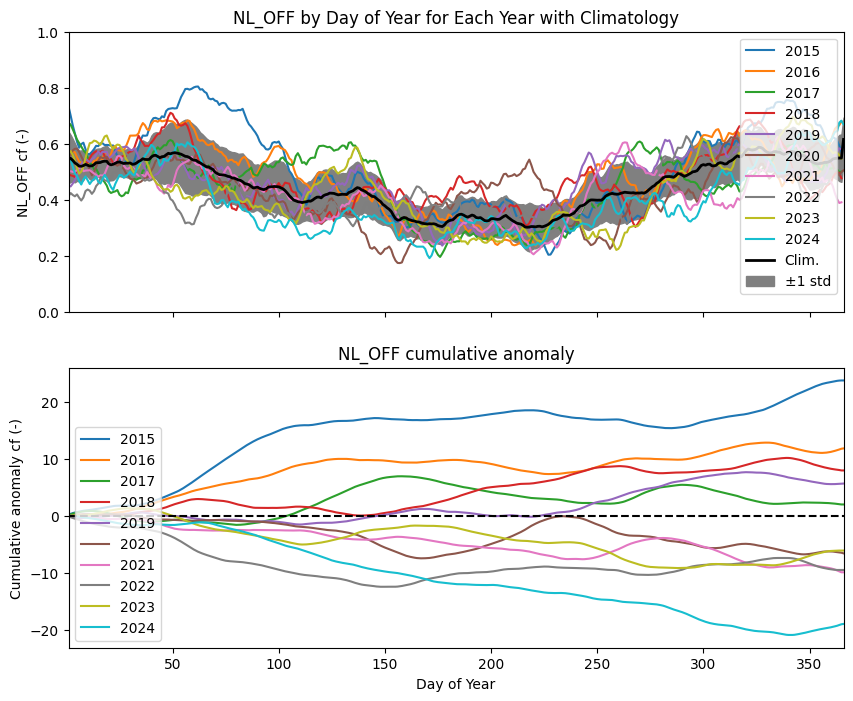

In [266]:
plot_clim_and_cum_anom(df_nl_rolling, "NL_OFF")

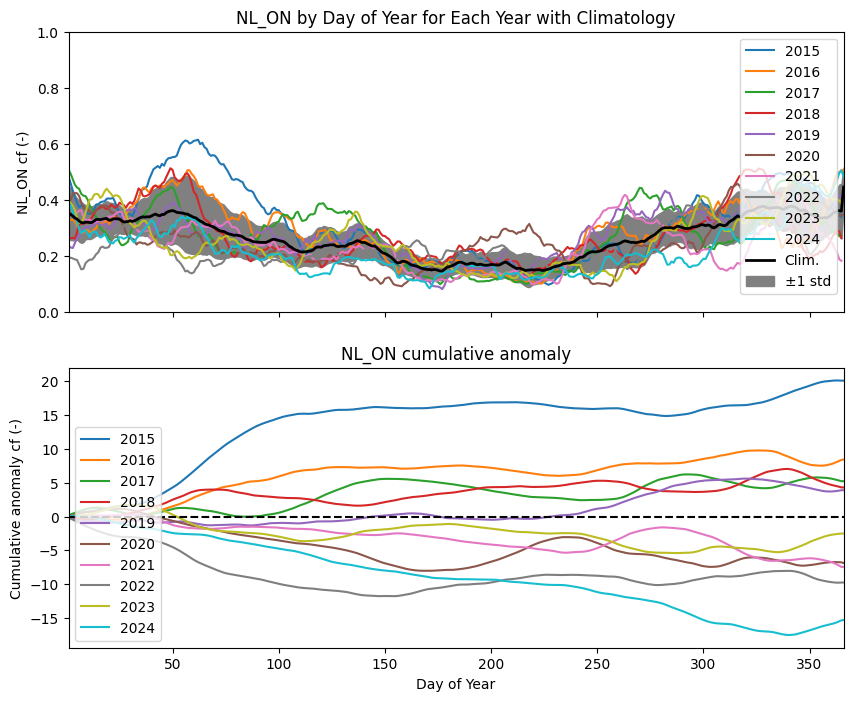

In [267]:
plot_clim_and_cum_anom(df_nl_rolling, "NL_ON")

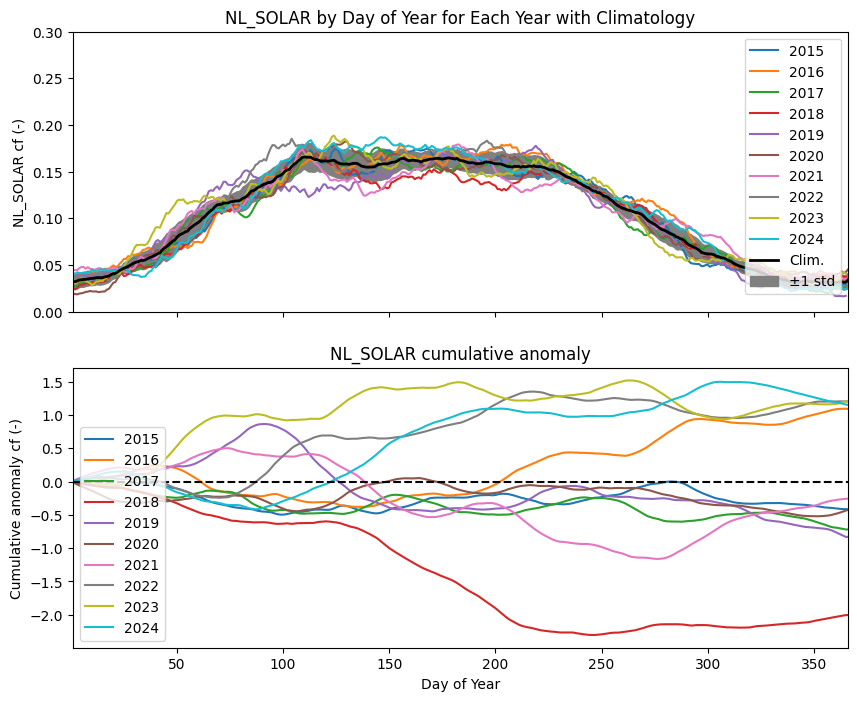

In [268]:
plot_clim_and_cum_anom(df_nl_rolling, "NL_SOLAR")

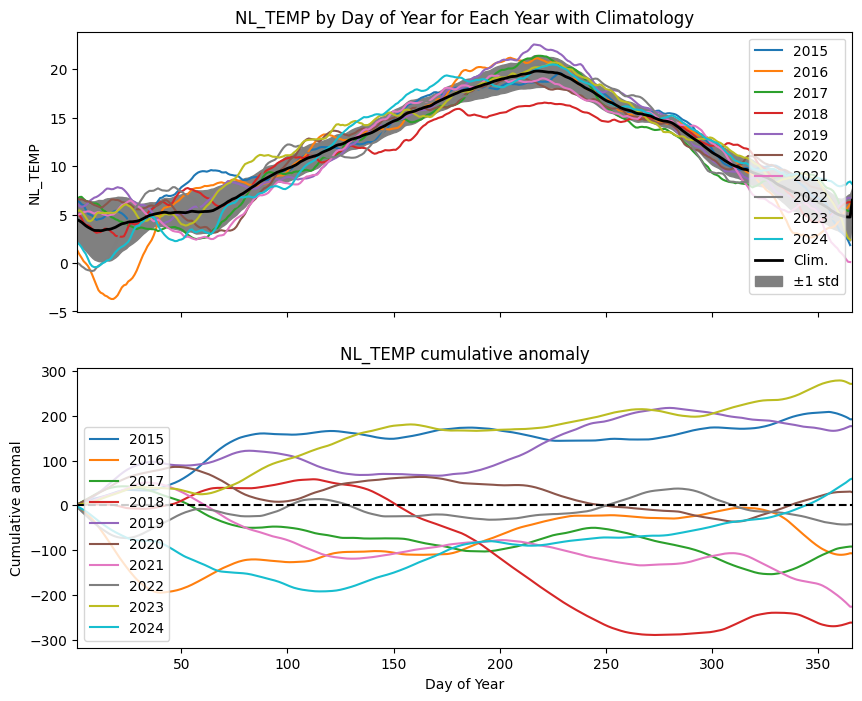

In [269]:
plot_clim_and_cum_anom(df_nl_rolling, "NL_TEMP")

# 3. Check anomaly w.r.t. climatology per year

In [135]:
climatological_means = df_nl.mean(axis=0)
yearly_means = df_nl.groupby(df_nl.index.year).agg("mean")
# normalize it by the climatological mean, and convert into percentage
yearly_mean_anom_norm = (
    (yearly_means - climatological_means) * 100 / climatological_means
)
# make sure that CDDs of zero are not plotted here, not really necessary I think
# yearly_mean_anom_norm.where(yearly_mean_anom_norm != -100, np.nan, inplace=True)

climatological_stds = df_nl.std(axis=0)
yearly_stds = df_nl.groupby(df_nl.index.year).agg("std")
# normalize it by the climatological std, and convert into percentage
yearly_std_anom_norm = (yearly_stds - climatological_stds) * 100 / climatological_stds

climatological_means

NL_OFF           0.449796
NL_ON            0.262943
NL_SOLAR         0.106767
NL_TEMP         11.547389
NL_T_daymean    11.547389
CDD              0.003159
HDD              2.879522
dtype: float64

(-50.0, 50.0)

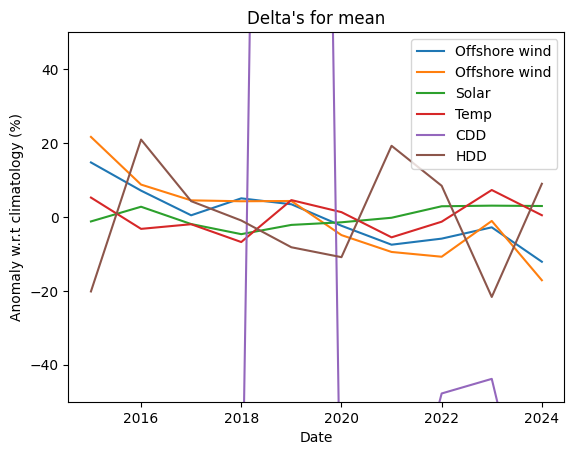

In [136]:
# NOTE: CDD is out of bounds for these plotting ylims.

yearly_mean_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_mean_anom_norm["NL_T_daymean"].plot(label="Temp")
yearly_mean_anom_norm["CDD"].plot(label="CDD")
yearly_mean_anom_norm["HDD"].plot(label="HDD")

plt.legend()
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for mean")
plt.ylim(-50, 50)

(-50.0, 50.0)

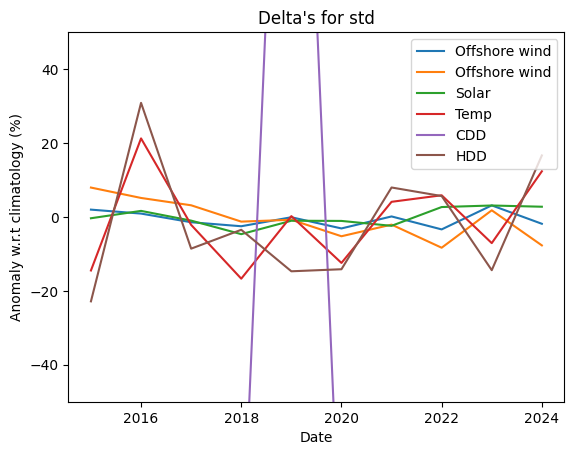

In [137]:
yearly_std_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_std_anom_norm["NL_T_daymean"].plot(label="Temp")
yearly_std_anom_norm["CDD"].plot(label="CDD")
yearly_std_anom_norm["HDD"].plot(label="HDD")


plt.legend(loc="upper right")
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for std")
plt.ylim(-50, 50)

# 4. Vibe-coded K-means clustering (CHECK!)

In [138]:
# make sure the index is datetime
df_standardized.index = pd.to_datetime(df_standardized.index, errors="coerce")

# one row = one year, features = mean & variance of every variable
yearly_stats = df_standardized.groupby(df_standardized.index.year).agg(["mean", "var"])
yearly_stats.columns = [f"{col}_{stat}" for col, stat in yearly_stats.columns]

# scale the year‑level feature matrix
X = StandardScaler().fit_transform(yearly_stats)

# pick the best k (2…10 or up to N‑1 years) with the silhouette score
k_grid = range(2, min(10, len(yearly_stats)))
silh = [
    silhouette_score(
        X, KMeans(n_clusters=k, n_init="auto", random_state=0).fit_predict(X)
    )
    for k in k_grid
]
k_best = k_grid[int(np.argmax(silh))]

# final clustering of the years
km = KMeans(n_clusters=k_best, n_init="auto", random_state=0).fit(X)
yearly_stats["cluster"] = km.labels_

print(f"chosen k = {k_best}")
print(yearly_stats[["cluster"]])


chosen k = 3
      cluster
Date         
2015        1
2016        1
2017        0
2018        0
2019        1
2020        0
2021        0
2022        2
2023        1
2024        2


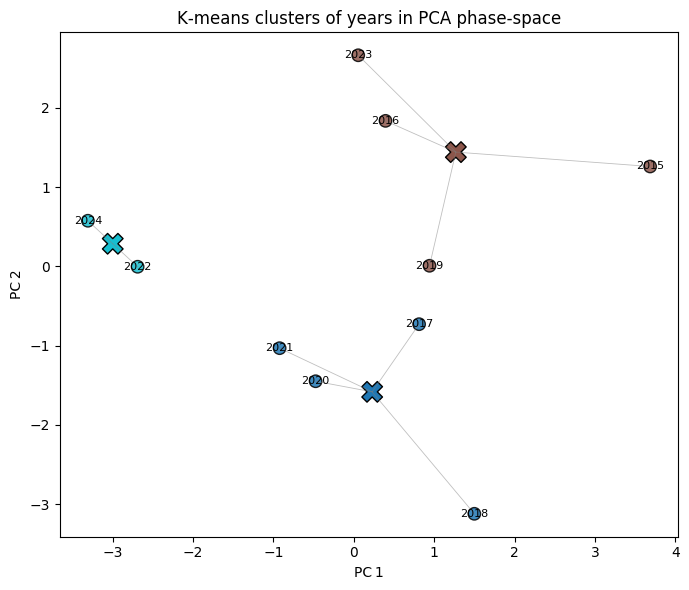

In [139]:
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)  # (n_years, 2)
centers_pca = pca.transform(km.cluster_centers_)  # (k, 2)

fig, ax = plt.subplots(figsize=(7, 6))

# years as coloured dots
pts = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=km.labels_,
    cmap="tab10",
    s=80,
    alpha=0.85,
    edgecolor="k",
)

# lines to centroids (distance visualisation)
for i, (x, y) in enumerate(X_pca):
    cx, cy = centers_pca[km.labels_[i]]
    ax.plot([x, cx], [y, cy], lw=0.6, color="grey", alpha=0.5)

# centroids as large X‑markers
ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    c=range(len(centers_pca)),
    cmap="tab10",
    s=220,
    edgecolor="k",
)

# optional: label the points with the calendar year
for i, year in enumerate(yearly_stats.index):
    ax.text(
        X_pca[i, 0],
        X_pca[i, 1],
        str(year),
        fontsize=8,
        ha="center",
        va="center",
    )

ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("K‑means clusters of years in PCA phase‑space")
plt.tight_layout()
plt.show()


In [140]:
# columns are ['NL_OFF_mean', 'NL_OFF_var', 'NL_ON_mean', 'NL_ON_var',
#              'NL_SOLAR_mean', 'NL_SOLAR_var', 'NL_T_daymean_mean', 'NL_T_daymean_var']
loadings = pd.DataFrame(
    pca.components_.T,  # shape (n_feats, n_components)
    index=yearly_stats.columns[:-1],  # drop 'cluster'
    columns=["PC1", "PC2"],
).round(3)

print("PCA loadings (coefficients):")
print(loadings)
print("\nExplained variance ratio:", pca.explained_variance_ratio_.round(3))


PCA loadings (coefficients):
                     PC1    PC2
NL_OFF_mean        0.481  0.064
NL_OFF_var         0.251  0.460
NL_ON_mean         0.497  0.113
NL_ON_var          0.445  0.243
NL_SOLAR_mean     -0.318  0.470
NL_SOLAR_var      -0.260  0.508
NL_T_daymean_mean  0.107  0.410
NL_T_daymean_var  -0.285  0.255

Explained variance ratio: [0.46  0.323]


In [141]:
# undo the StandardScaler we fitted just before PCA
year_centroids_unscaled = pd.DataFrame(
    StandardScaler()
    .fit(yearly_stats.iloc[:, :-1])
    .inverse_transform(km.cluster_centers_),
    columns=yearly_stats.columns[:-1],
    index=[f"cluster_{c}" for c in range(k_best)],
).round(2)

# map feature → (μ, σ) from the first scaler
orig_mu = dict(zip(scaler.feature_names_in_, scaler.mean_))
orig_sigma = dict(zip(scaler.feature_names_in_, scaler.scale_))

centroids_phys = year_centroids_unscaled.copy()  # don’t overwrite yet

for feat in ["NL_OFF", "NL_ON", "NL_SOLAR", "NL_T_daymean"]:
    mu = orig_mu[feat]
    sig = orig_sigma[feat]

    # mean:  x = z·σ + μ
    centroids_phys[f"{feat}_mean"] = centroids_phys[f"{feat}_mean"] * sig + mu

    # variance:  Var(x) = Var(z)·σ²
    centroids_phys[f"{feat}_var"] = centroids_phys[f"{feat}_var"] * sig**2

# tidy up (optional): round and/or rename columns
centroids_phys = centroids_phys.round(2)

print("Cluster centroids back in physical units:")
display(centroids_phys)


Cluster centroids back in physical units:


,NL_OFF_mean,NL_OFF_var,NL_ON_mean,NL_ON_var,NL_SOLAR_mean,NL_SOLAR_var,NL_T_daymean_mean,NL_T_daymean_var
cluster_0,0.44,0.09,0.26,0.06,0.11,0.03,11.18,32.59
cluster_1,0.47,0.10,0.29,0.07,0.11,0.03,11.97,37.77
cluster_2,0.41,0.09,0.23,0.05,0.11,0.03,11.49,44.07
